In [1]:
!pip install openpyxl joblib scikit-learn

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

import joblib
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
from google.colab import files

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [6]:
df = pd.read_excel("Online Retail.xlsx")

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [7]:
print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [8]:
print("Dataset Shape:", df.shape)

Dataset Shape: (541909, 8)


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [10]:
print(df.describe())

            Quantity                    InvoiceDate      UnitPrice  \
count  541909.000000                         541909  541909.000000   
mean        9.552250  2011-07-04 13:34:57.156386048       4.611114   
min    -80995.000000            2010-12-01 08:26:00  -11062.060000   
25%         1.000000            2011-03-28 11:34:00       1.250000   
50%         3.000000            2011-07-19 17:17:00       2.080000   
75%        10.000000            2011-10-19 11:27:00       4.130000   
max     80995.000000            2011-12-09 12:50:00   38970.000000   
std       218.081158                            NaN      96.759853   

          CustomerID  
count  406829.000000  
mean    15287.690570  
min     12346.000000  
25%     13953.000000  
50%     15152.000000  
75%     16791.000000  
max     18287.000000  
std      1713.600303  


In [11]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [12]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 5268


In [13]:
df = df.drop_duplicates()

print("Duplicates removed:", df.duplicated().sum())

Duplicates removed: 0


In [14]:
df = df.dropna(subset=[
    "CustomerID",
    "Description"
])

print(df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [15]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

df = df[
    ~df["InvoiceNo"].str.startswith("C")
]

In [16]:
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

print(df.shape)

(392692, 8)


In [17]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"]
)

print(df["InvoiceDate"].dtype)

datetime64[ns]


In [18]:
df["TotalPrice"] = (
    df["Quantity"] * df["UnitPrice"]
)

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalPrice  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom       15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom       22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  


In [19]:
df.to_csv(
    "cleaned_transaction_dataset.csv",
    index=False
)

print("Cleaned dataset saved!")

Cleaned dataset saved!


In [20]:
print(
    "Unique Customers:",
    df["CustomerID"].nunique()
)

print(
    "Total Transactions:",
    df["InvoiceNo"].nunique()
)

print(
    "Total Revenue:",
    round(df["TotalPrice"].sum(), 2)
)

Unique Customers: 4338
Total Transactions: 18532
Total Revenue: 8887208.89


In [21]:
top_products = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


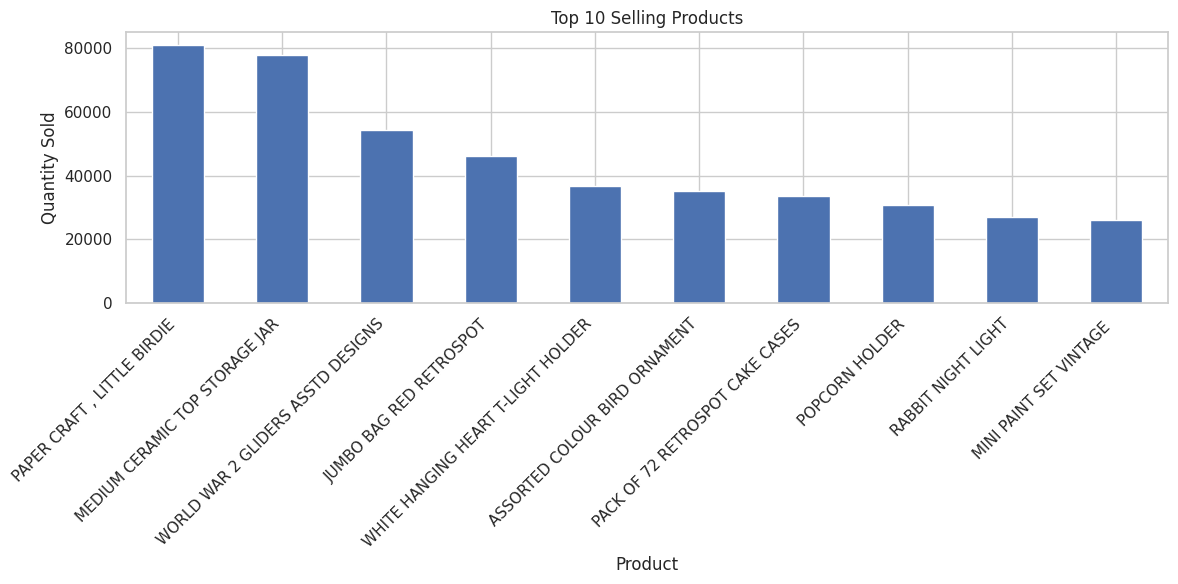

In [22]:
plt.figure(figsize=(12, 6))

top_products.plot(kind="bar")

plt.title("Top 10 Selling Products")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("charts_top_10_products.png")
plt.show()

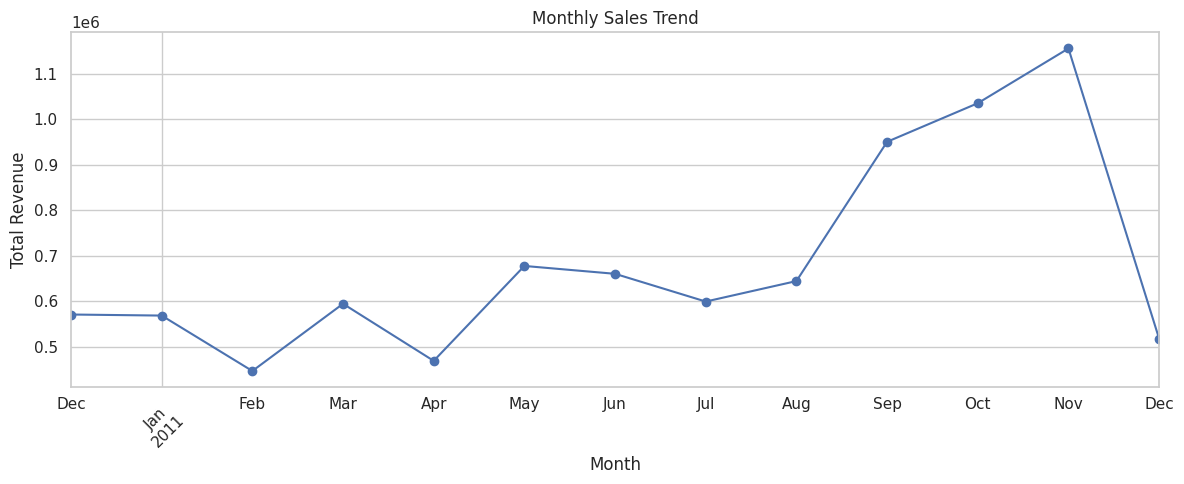

In [23]:
df["Month"] = df["InvoiceDate"].dt.to_period("M")

monthly_sales = (
    df.groupby("Month")["TotalPrice"]
    .sum()
)

plt.figure(figsize=(12, 5))

monthly_sales.plot(marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("charts_monthly_sales_trend.png")
plt.show()

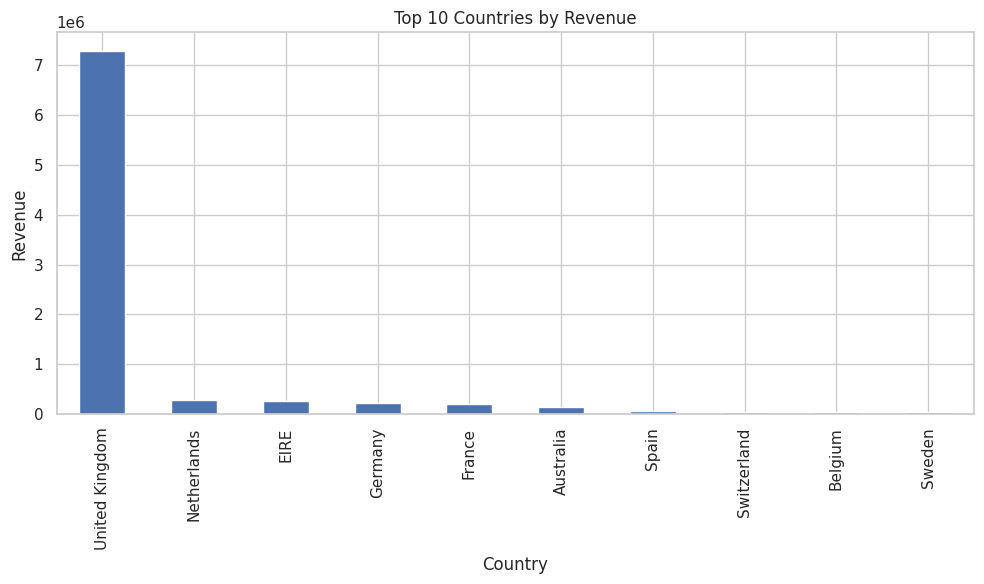

In [24]:
country_sales = (
    df.groupby("Country")["TotalPrice"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

country_sales.plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.ylabel("Revenue")

plt.tight_layout()

plt.savefig("charts_country_sales_analysis.png")
plt.show()

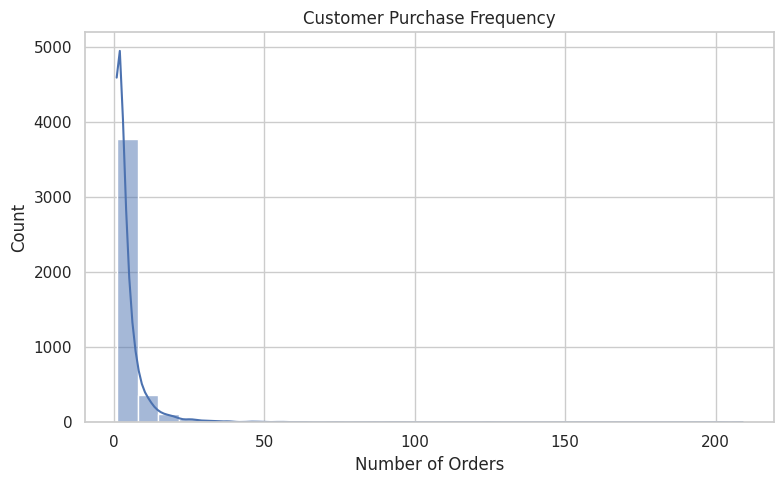

In [25]:
customer_orders = df.groupby(
    "CustomerID"
)["InvoiceNo"].nunique()

plt.figure(figsize=(8, 5))

sns.histplot(customer_orders, bins=30, kde=True)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")

plt.tight_layout()
plt.savefig("charts_customer_distribution.png")
plt.show()

In [26]:
reference_date = (
    df["InvoiceDate"].max() +
    pd.Timedelta(days=1)
)

print("Reference Date:", reference_date)

Reference Date: 2011-12-10 12:50:00


In [27]:
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x:
        (reference_date - x.max()).days,

    "InvoiceNo": "nunique",

    "TotalPrice": "sum"
})

rfm.columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40


In [28]:
print(rfm.describe())

           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


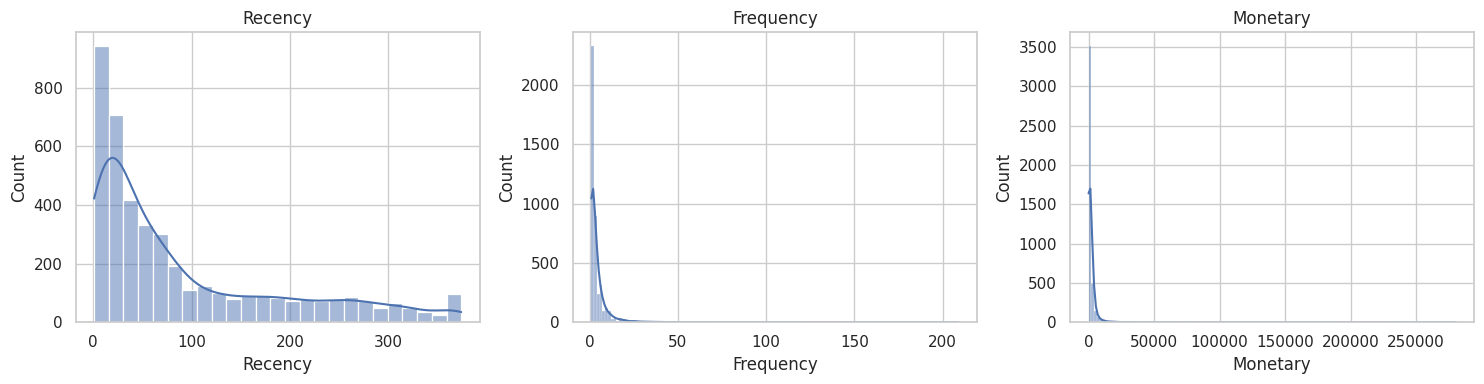

In [29]:
plt.figure(figsize=(15, 4))

for i, column in enumerate(
    ["Recency", "Frequency", "Monetary"]
):
    plt.subplot(1, 3, i + 1)

    sns.histplot(rfm[column], kde=True)

    plt.title(column)

plt.tight_layout()

plt.savefig("charts_rfm_distribution.png")
plt.show()

In [30]:
rfm.to_csv("customer_features_rfm.csv")

print("RFM features exported!")

RFM features exported!


In [31]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)

print("Feature scaling completed!")

Feature scaling completed!


In [32]:
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=rfm.columns,
    index=rfm.index
)

print(rfm_scaled_df.head())

             Recency  Frequency  Monetary
CustomerID                               
12346.0     2.334574  -0.425097  8.363010
12347.0    -0.905340   0.354417  0.251699
12348.0    -0.175360  -0.035340 -0.027988
12349.0    -0.735345  -0.425097 -0.032406
12350.0     2.174578  -0.425097 -0.190812


In [33]:
wcss = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled_df)

    wcss.append(kmeans.inertia_)

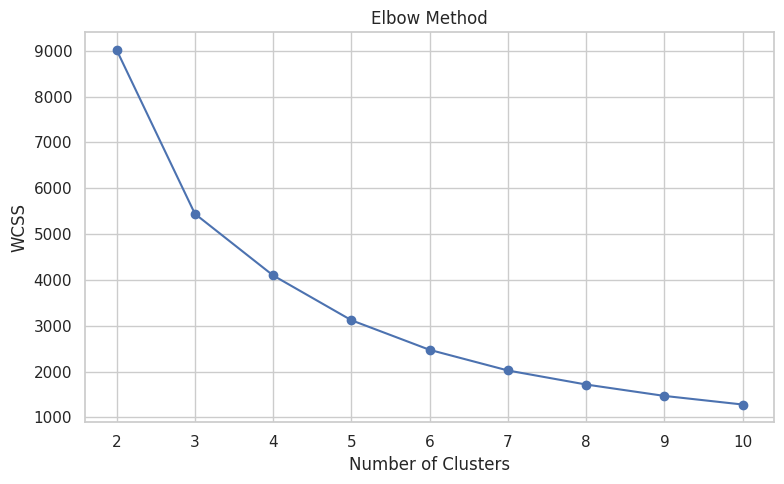

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.tight_layout()

plt.savefig("charts_elbow_method.png")
plt.show()

In [35]:
silhouette_scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled_df)

    score = silhouette_score(
        rfm_scaled_df,
        labels
    )

    silhouette_scores.append(score)

    print(
        "Clusters:", k,
        "Silhouette Score:", round(score, 4)
    )

Clusters: 2 Silhouette Score: 0.8958
Clusters: 3 Silhouette Score: 0.5942
Clusters: 4 Silhouette Score: 0.6162
Clusters: 5 Silhouette Score: 0.6165
Clusters: 6 Silhouette Score: 0.5983
Clusters: 7 Silhouette Score: 0.5165
Clusters: 8 Silhouette Score: 0.4859
Clusters: 9 Silhouette Score: 0.4784
Clusters: 10 Silhouette Score: 0.4792


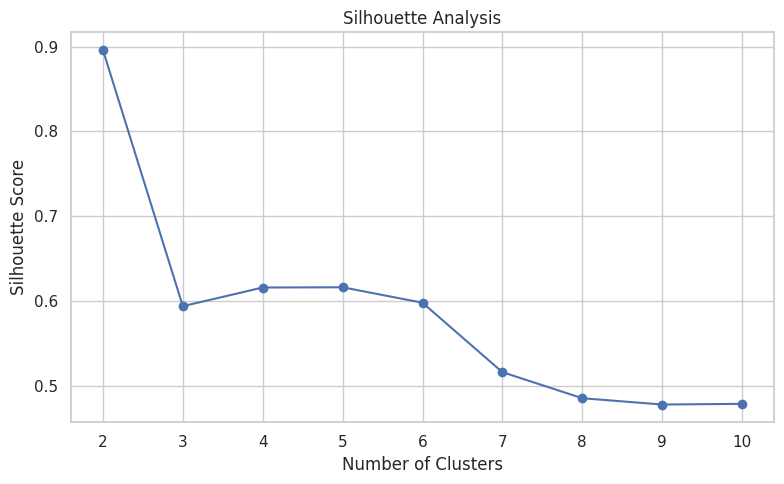

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Analysis")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.tight_layout()

plt.savefig("charts_silhouette_analysis.png")
plt.show()

In [37]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(
    rfm_scaled_df
)

print(rfm.head())

            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346.0         326          1  77183.60        3
12347.0           2          7   4310.00        0
12348.0          75          4   1797.24        0
12349.0          19          1   1757.55        0
12350.0         310          1    334.40        1


In [38]:
print(
    rfm["Cluster"].value_counts().sort_index()
)

Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


In [39]:
rfm.to_csv("customer_segments.csv")

print("Customer segmentation completed!")

Customer segmentation completed!


In [40]:
cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

print(cluster_summary)

         Recency  Frequency   Monetary
Cluster                               
0          43.70       3.68    1353.63
1         248.08       1.55     478.85
2           7.38      82.54  127187.96
3          15.50      22.33   12690.50


In [41]:
def segment_customer(row):

    if (
        row["Recency"] < 30 and
        row["Frequency"] >= 5 and
        row["Monetary"] >= rfm["Monetary"].median()
    ):
        return "Champions"

    elif (
        row["Recency"] <= 90 and
        row["Frequency"] >= 3
    ):
        return "Regular Customers"

    elif row["Recency"] > 180:
        return "At-Risk Customers"

    else:
        return "Occasional Buyers"


rfm["Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

print(rfm[["Cluster", "Segment"]].head())

            Cluster            Segment
CustomerID                            
12346.0           3  At-Risk Customers
12347.0           0          Champions
12348.0           0  Regular Customers
12349.0           0  Occasional Buyers
12350.0           1  At-Risk Customers


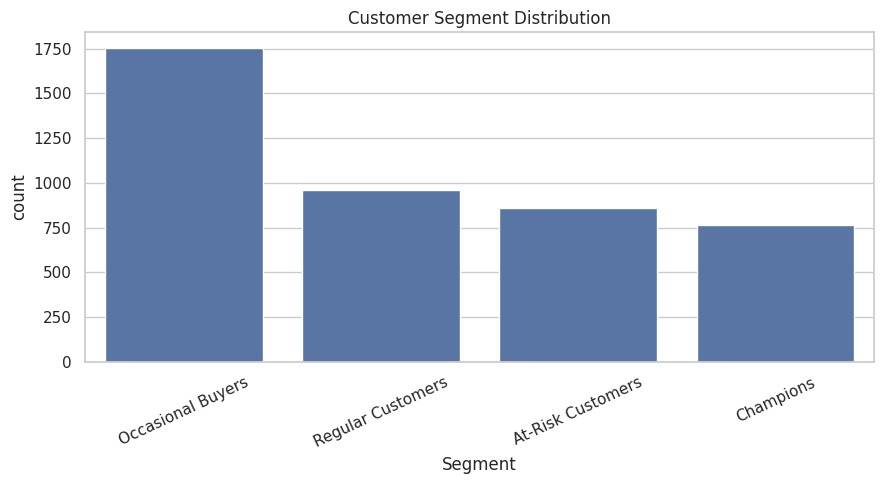

In [42]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm.reset_index(),
    x="Segment",
    order=rfm["Segment"].value_counts().index
)

plt.title("Customer Segment Distribution")

plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig("charts_customer_segment_distribution.png")
plt.show()

In [43]:
segment_summary = rfm.groupby("Segment").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean",
    "Cluster": "count"
}).round(2)

segment_summary = segment_summary.rename(
    columns={"Cluster": "Customer_Count"}
)

print(segment_summary)

                   Recency  Frequency  Monetary  Customer_Count
Segment                                                        
At-Risk Customers   269.12       1.50    645.15             860
Champions            10.88      12.70   6899.24             767
Occasional Buyers    71.71       1.75    717.89            1753
Regular Customers    37.50       4.62   1860.33             958


In [44]:
segment_summary.to_csv(
    "customer_segment_summary.csv"
)

print("Segment summary exported!")

Segment summary exported!


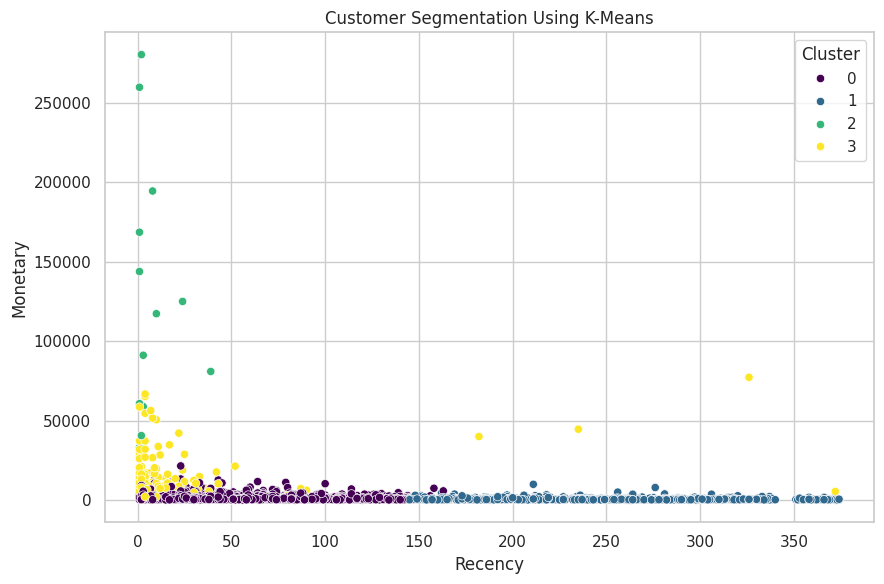

In [45]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm.reset_index(),
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="viridis"
)

plt.title("Customer Segmentation Using K-Means")

plt.tight_layout()

plt.savefig("charts_customer_clusters.png")
plt.show()

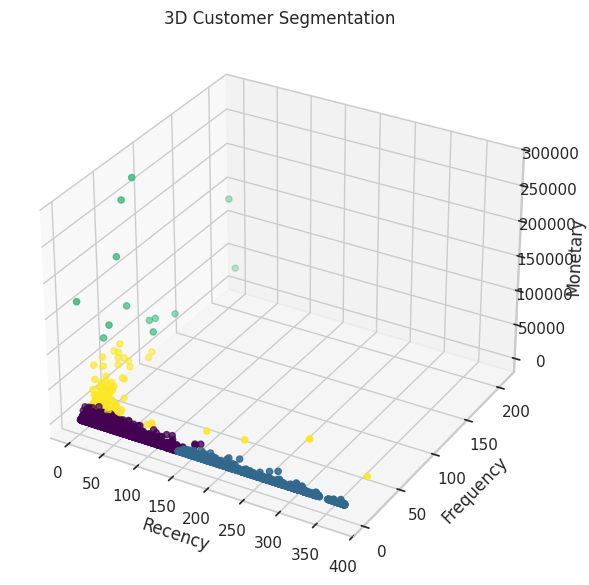

In [46]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    rfm["Recency"],
    rfm["Frequency"],
    rfm["Monetary"],
    c=rfm["Cluster"],
    cmap="viridis"
)

ax.set_xlabel("Recency")
ax.set_ylabel("Frequency")
ax.set_zlabel("Monetary")

ax.set_title("3D Customer Segmentation")

plt.savefig("charts_cluster_3d_visualization.png")

plt.show()

In [47]:
customer_product = df.pivot_table(
    index="CustomerID",
    columns="Description",
    values="Quantity",
    aggfunc="sum",
    fill_value=0
)

print(customer_product.shape)

(4338, 3877)


In [48]:
popular_products = (
    customer_product.sum()
    .sort_values(ascending=False)
    .head(500)
    .index
)

customer_product = customer_product[
    popular_products
]

print(customer_product.shape)

(4338, 500)


In [49]:
product_similarity = cosine_similarity(
    customer_product.T
)

product_similarity_df = pd.DataFrame(
    product_similarity,
    index=customer_product.columns,
    columns=customer_product.columns
)

print(product_similarity_df.head())

Description                         PAPER CRAFT , LITTLE BIRDIE  \
Description                                                       
PAPER CRAFT , LITTLE BIRDIE                                 1.0   
MEDIUM CERAMIC TOP STORAGE JAR                              0.0   
WORLD WAR 2 GLIDERS ASSTD DESIGNS                           0.0   
JUMBO BAG RED RETROSPOT                                     0.0   
WHITE HANGING HEART T-LIGHT HOLDER                          0.0   

Description                         MEDIUM CERAMIC TOP STORAGE JAR  \
Description                                                          
PAPER CRAFT , LITTLE BIRDIE                               0.000000   
MEDIUM CERAMIC TOP STORAGE JAR                            1.000000   
WORLD WAR 2 GLIDERS ASSTD DESIGNS                         0.000216   
JUMBO BAG RED RETROSPOT                                   0.001315   
WHITE HANGING HEART T-LIGHT HOLDER                        0.000526   

Description                         WOR

In [50]:
def recommend_products(product_name, top_n=5):

    if product_name not in product_similarity_df.columns:
        return "Product not found!"

    scores = product_similarity_df[product_name]

    recommendations = (
        scores.drop(product_name)
        .sort_values(ascending=False)
        .head(top_n)
    )

    return recommendations

In [51]:
sample_product = customer_product.columns[0]

print("Selected Product:", sample_product)

print("\nRecommended Products:")

print(
    recommend_products(sample_product)
)

Selected Product: PAPER CRAFT , LITTLE BIRDIE

Recommended Products:
Description
MEDIUM CERAMIC TOP STORAGE JAR        0.0
WORLD WAR 2 GLIDERS ASSTD DESIGNS     0.0
JUMBO BAG RED RETROSPOT               0.0
WHITE HANGING HEART T-LIGHT HOLDER    0.0
ASSORTED COLOUR BIRD ORNAMENT         0.0
Name: PAPER CRAFT , LITTLE BIRDIE, dtype: float64


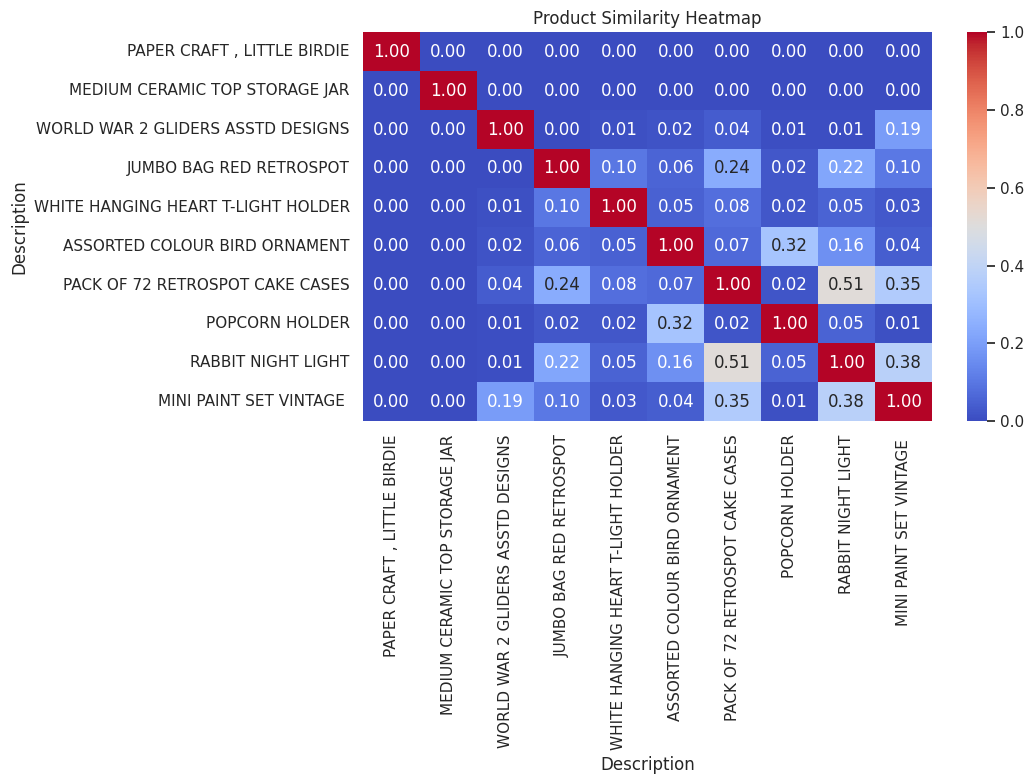

In [52]:
sample_products = (
    customer_product.sum()
    .sort_values(ascending=False)
    .head(10)
    .index
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    product_similarity_df.loc[
        sample_products,
        sample_products
    ],
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Product Similarity Heatmap")

plt.tight_layout()

plt.savefig("charts_product_similarity_heatmap.png")
plt.show()

In [53]:
def recommend_for_customer(customer_id, top_n=5):

    if customer_id not in customer_product.index:
        return "Customer not found!"

    purchased = customer_product.loc[customer_id]

    purchased = purchased[purchased > 0]

    if purchased.empty:
        return "No purchase history available."

    scores = product_similarity_df[
        purchased.index
    ].mean(axis=1)

    scores = scores.drop(
        purchased.index,
        errors="ignore"
    )

    return scores.sort_values(
        ascending=False
    ).head(top_n)

In [54]:
sample_customer = customer_product.index[0]

print("Customer ID:", sample_customer)

print(
    recommend_for_customer(sample_customer)
)

Customer ID: 12346.0
Description
LARGE CERAMIC TOP STORAGE JAR        0.008958
TRAVEL SEWING KIT                    0.007584
PACK OF 12 PINK PAISLEY TISSUES      0.007298
PACK OF 12 RED RETROSPOT TISSUES     0.007018
GREEN REGENCY TEACUP AND SAUCER      0.006407
dtype: float64


In [55]:
business_advice = {
    "Champions":
        "Provide loyalty rewards, exclusive offers and early access to new products.",

    "Regular Customers":
        "Encourage repeat purchases through personalized offers and product bundles.",

    "Occasional Buyers":
        "Use targeted discounts and product recommendations to increase engagement.",

    "At-Risk Customers":
        "Use re-engagement campaigns, special offers and reminders."
}

rfm["Business_Recommendation"] = (
    rfm["Segment"].map(business_advice)
)

print(
    rfm[[
        "Segment",
        "Business_Recommendation"
    ]].head()
)

                      Segment  \
CustomerID                      
12346.0     At-Risk Customers   
12347.0             Champions   
12348.0     Regular Customers   
12349.0     Occasional Buyers   
12350.0     At-Risk Customers   

                                      Business_Recommendation  
CustomerID                                                     
12346.0     Use re-engagement campaigns, special offers an...  
12347.0     Provide loyalty rewards, exclusive offers and ...  
12348.0     Encourage repeat purchases through personalize...  
12349.0     Use targeted discounts and product recommendat...  
12350.0     Use re-engagement campaigns, special offers an...  


In [56]:
recommendation_records = []

for customer_id in customer_product.index:

    result = recommend_for_customer(
        customer_id,
        top_n=5
    )

    if isinstance(result, pd.Series):

        for product, score in result.items():

            recommendation_records.append({
                "CustomerID": customer_id,
                "Recommended_Product": product,
                "Similarity_Score": score
            })

recommendations_df = pd.DataFrame(
    recommendation_records
)

print(recommendations_df.head())

   CustomerID                Recommended_Product  Similarity_Score
0     12346.0      LARGE CERAMIC TOP STORAGE JAR          0.008958
1     12346.0                  TRAVEL SEWING KIT          0.007584
2     12346.0   PACK OF 12 PINK PAISLEY TISSUES           0.007298
3     12346.0  PACK OF 12 RED RETROSPOT TISSUES           0.007018
4     12346.0    GREEN REGENCY TEACUP AND SAUCER          0.006407


In [57]:
recommendations_df.to_csv(
    "product_recommendations.csv",
    index=False
)

print("Product recommendations exported!")

Product recommendations exported!


In [58]:
product_similarity_df.to_csv(
    "product_similarity_matrix.csv"
)

print("Product similarity matrix exported!")

Product similarity matrix exported!


In [59]:
final_silhouette = silhouette_score(
    rfm_scaled_df,
    rfm["Cluster"]
)

print(
    "Silhouette Score:",
    round(final_silhouette, 4)
)

print(
    "Inertia:",
    round(kmeans.inertia_, 2)
)

Silhouette Score: 0.6162
Inertia: 4096.3


In [60]:
evaluation_summary = pd.DataFrame({
    "Metric": [
        "Number of Clusters",
        "Silhouette Score",
        "Inertia",
        "Number of Customers",
        "Number of Products"
    ],

    "Value": [
        4,
        final_silhouette,
        kmeans.inertia_,
        len(rfm),
        customer_product.shape[1]
    ]
})

print(evaluation_summary)

                Metric        Value
0   Number of Clusters     4.000000
1     Silhouette Score     0.616228
2              Inertia  4096.300211
3  Number of Customers  4338.000000
4   Number of Products   500.000000


In [61]:
evaluation_summary.to_csv(
    "evaluation_summary.csv",
    index=False
)

print("Evaluation summary saved!")

Evaluation summary saved!


In [62]:
print("PROJECT SUMMARY")

print("-----------------------------")

print("Total Transactions:", len(df))

print("Unique Customers:", len(rfm))

print("Customer Segments:",
      rfm["Segment"].nunique())

print("Products Analyzed:",
      customer_product.shape[1])

print("Silhouette Score:",
      round(final_silhouette, 4))

print("-----------------------------")

print("Project Completed Successfully!")

PROJECT SUMMARY
-----------------------------
Total Transactions: 392692
Unique Customers: 4338
Customer Segments: 4
Products Analyzed: 500
Silhouette Score: 0.6162
-----------------------------
Project Completed Successfully!


In [63]:
model_package = {
    "scaler": scaler,
    "kmeans": kmeans,
    "features": ["Recency", "Frequency", "Monetary"]
}

joblib.dump(
    model_package,
    "ecommerce_customer_model.joblib"
)

print("Customer segmentation model saved!")

Customer segmentation model saved!


In [64]:
loaded_model = joblib.load(
    "ecommerce_customer_model.joblib"
)

sample_scaled = loaded_model["scaler"].transform(
    rfm[["Recency", "Frequency", "Monetary"]].iloc[:5]
)

sample_clusters = loaded_model["kmeans"].predict(
    sample_scaled
)

print("Sample Customer Clusters:")

print(sample_clusters)

Sample Customer Clusters:
[3 0 0 0 1]


In [65]:
import os

os.makedirs("charts", exist_ok=True)
os.makedirs("screenshots", exist_ok=True)

In [66]:
df.to_csv(
    "cleaned_transaction_dataset.csv",
    index=False
)

rfm.to_csv(
    "customer_segments.csv"
)

rfm.drop(
    columns=["Cluster", "Segment",
             "Business_Recommendation"],
    errors="ignore"
).to_csv(
    "customer_features_rfm.csv"
)

cluster_summary.to_csv(
    "customer_cluster_summary.csv"
)

segment_summary.to_csv(
    "customer_segment_summary.csv"
)

print("All datasets exported!")

All datasets exported!


In [68]:
from google.colab import files
download_files = [
    "cleaned_transaction_dataset.csv",
    "customer_features_rfm.csv",
    "customer_segments.csv",
    "customer_segment_summary.csv",
    "product_similarity_matrix.csv",
    "product_recommendations.csv",
    "business_recommendations.csv",
    "evaluation_summary.csv",
    "ecommerce_customer_model.joblib"
]

In [69]:
plt.savefig("sales_trend.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [70]:
plt.savefig("monthly_sales_trend.png", dpi=300, bbox_inches="tight")
plt.savefig("top_10_products.png", dpi=300, bbox_inches="tight")
plt.savefig("country_wise_sales.png", dpi=300, bbox_inches="tight")
plt.savefig("elbow_method.png", dpi=300, bbox_inches="tight")
plt.savefig("silhouette_analysis.png", dpi=300, bbox_inches="tight")
plt.savefig("customer_clusters.png", dpi=300, bbox_inches="tight")
plt.savefig("customer_segment_distribution.png", dpi=300, bbox_inches="tight")
plt.savefig("product_similarity_heatmap.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [71]:
from google.colab import files

files.download("monthly_sales_trend.png")
files.download("top_10_products.png")
files.download("country_wise_sales.png")
files.download("elbow_method.png")
files.download("silhouette_analysis.png")
files.download("customer_clusters.png")
files.download("customer_segment_distribution.png")
files.download("product_similarity_heatmap.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>